# Ataques Adversariais: Comprometendo Sistemas Baseados em Machine Learning

## Importações

In [1]:
!pip install gdown

import gdown

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from PIL import Image
import matplotlib.pyplot as plt
import os
import random
import numpy as np
import zipfile
import shutil

## Carregamento de Dados

In [23]:
!gdown --folder https://drive.google.com/drive/folders/1ZJIITWgAplI4_Aohj_Hw5Nuz9KEw_ZhM

Retrieving folder contents
Processing file 1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp cats_dogs_small.zip
Processing file 1eSkfzfI50ayZJvMPZp2XPCSXqt4Qu1JC glasses_no_glasses.zip
Processing file 1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQFBh mask_no_mask.zip
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp
From (redirected): https://drive.google.com/uc?id=1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp&confirm=t&uuid=ca14bd86-fe5c-4ea2-9e94-f5d3624a8dd0
To: /content/Data/cats_dogs_small.zip
100% 32.3M/32.3M [00:00<00:00, 173MB/s]
Downloading...
From: https://drive.google.com/uc?id=1eSkfzfI50ayZJvMPZp2XPCSXqt4Qu1JC
To: /content/Data/glasses_no_glasses.zip
100% 3.96M/3.96M [00:00<00:00, 210MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQFBh
From (redirected): https://drive.google.com/uc?id=1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQFBh

In [23]:
data_path = "/content/Data"

zip_files = [f for f in os.listdir(data_path) if f.endswith(".zip")]

print("Datasets disponíveis:\n")
for i, file in enumerate(zip_files, 1):
    print(f"{i} - {file}")

choice = input("\nDigite o número do dataset: ")

try:
    choice = int(choice)
    selected_zip = zip_files[choice - 1]
except:
    raise ValueError("Opção inválida!")

zip_path = os.path.join(data_path, selected_zip)

extract_path = os.path.join(data_path, selected_zip.replace(".zip", ""))
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

extract_name = os.path.basename(os.path.normpath(extract_path))
subdirs = [d for d in os.listdir(extract_path) if os.path.isdir(os.path.join(extract_path, d))]
nested_path = os.path.join(extract_path, extract_name)
class_subdirs = [d for d in subdirs if d != extract_name]

if os.path.isdir(nested_path) and class_subdirs:
    shutil.rmtree(nested_path)
    subdirs = class_subdirs
elif os.path.isdir(nested_path):
    subdirs = [extract_name]

if len(subdirs) == 1:
    inner_path = os.path.join(extract_path, subdirs[0])

    for item in os.listdir(inner_path):
        shutil.move(os.path.join(inner_path, item), extract_path)

    os.rmdir(inner_path)

print(f"\nDataset escolhido: {selected_zip}")
print(f"Extraído em: {extract_path}")

Datasets disponíveis:

1 - glasses_no_glasses.zip
2 - cats_dogs_small.zip
3 - mask_no_mask.zip

Dataset escolhido: cats_dogs_small.zip
Extraído em: /content/Data/cats_dogs_small


In [24]:
data_dir = extract_path

In [25]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds, val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="both",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)



Found 1000 files belonging to 2 classes.
Using 800 files for training.
Using 200 files for validation.


In [22]:
print(train_ds.class_names)

['cats', 'dogs']


## Modelo de Classificação

In [16]:
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')
base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [17]:
model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3
24/25 ━━━━━━━━━━━━━━━━━━━━ 0s 789ms/step - accuracy: 0.6939 - loss: 0.5572

KeyboardInterrupt: 

In [11]:
model.evaluate(val_ds)

13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 690ms/step - accuracy: 0.4925 - loss: -5.2995


[-5.299452304840088, 0.4925000071525574]

## Mostrando as imagens

In [18]:
class_names = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]

paths = []

class_names = sorted(class_names)

for class_name in class_names:
    class_dir = os.path.join(data_dir, class_name)

    images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not images:
        continue

    chosen = random.choice(images)
    full_path = os.path.join(class_dir, chosen)

    paths.append(full_path)

if len(paths) >= 2:
    path_class1 = paths[0]
    path_class2 = paths[1]

print("Classe 1:", path_class1)
print("Classe 2:", path_class2)

Classe 1: /content/Data/cats_dogs_small/cats/6103.jpg
Classe 2: /content/Data/cats_dogs_small/dogs/11361.jpg


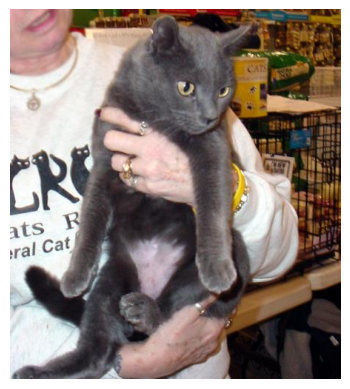

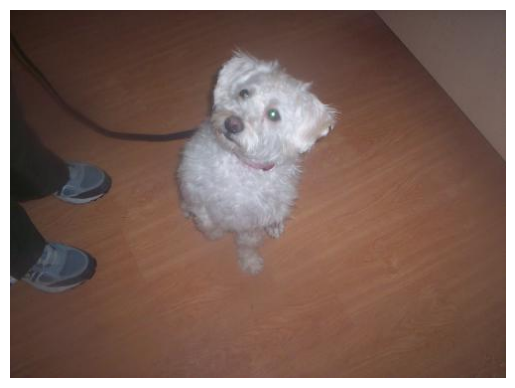

In [19]:
img_cat = Image.open(path_class1)
plt.imshow(img_cat)
plt.axis('off')
plt.show()

img_dog = Image.open(path_class2)
plt.imshow(img_dog)
plt.axis('off')
plt.show()

## Realizando a inferência

In [20]:
def predict_image(path, model, class_names):
    img = tf.keras.utils.load_img(path, target_size=(160,160))
    img = tf.keras.utils.img_to_array(img)

    img = tf.expand_dims(img, axis=0)

    pred = model.predict(img, verbose=0)[0][0]

    pred_class = int(pred >= 0.5)
    class_name = class_names[pred_class]

    confidence = pred if pred_class == 1 else 1 - pred

    return img, pred, class_name, confidence

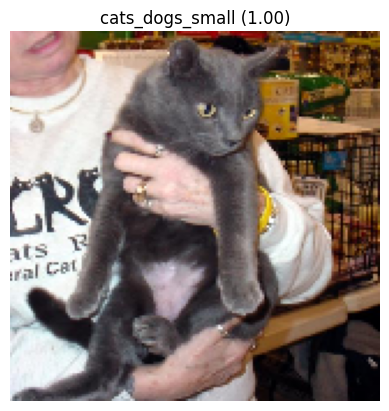

In [21]:
img, pred, classe, conf = predict_image(path_class1, model, class_names)

plt.imshow(img[0].numpy().astype("uint8"))
plt.title(f"{classe} ({conf:.2f})")
plt.axis('off')
plt.show()

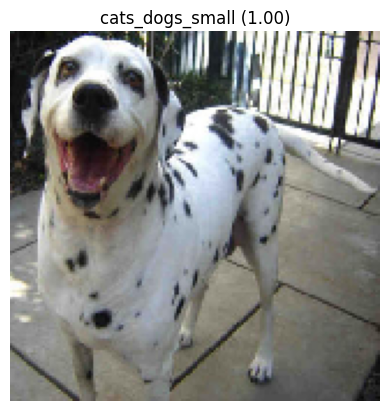

In [16]:
img, pred, classe, conf = predict_image(path_class2, model, class_names)

plt.imshow(img[0].numpy().astype("uint8"))
plt.title(f"{classe} ({conf:.2f})")
plt.axis('off')
plt.show()

# Ataques Iterativos - WhiteBox
## Bem-vindo ao CleverHans!

https://github.com/cleverhans-lab/cleverhans

## Instalando a biblioteca

In [16]:
! pip install cleverhans

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.3/92.3 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 9.6 MB/s eta 0:00:00


## BIM

### Importando o ataque iterativo

In [22]:
from cleverhans.tf2.attacks.basic_iterative_method import basic_iterative_method

ModuleNotFoundError: No module named 'cleverhans'

### Gerando o Exemplo Adversarial

In [31]:
desired_class = 0  # escolha 0 ou 1

for images, labels in val_ds.unbatch():
    if labels.numpy() == desired_class:
        x_input = tf.cast(tf.expand_dims(images, 0), tf.float32)
        y_true_ch = tf.cast(tf.reshape([labels], [-1]), tf.int32)
        break

In [32]:
def model_wrapper(x):
    prob_1 = model(x)
    prob_0 = 1.0 - prob_1
    return tf.concat([prob_0, prob_1], axis=1)

_ = model_wrapper(x_input)

In [33]:
# Craft adversarial sample
eps = 8.0
eps_iter = 1.0
nb_iter = 15

adv_x_bim = basic_iterative_method(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter, norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, sanity_checks=False)

### Realizando a classificação do exemplo adversarial


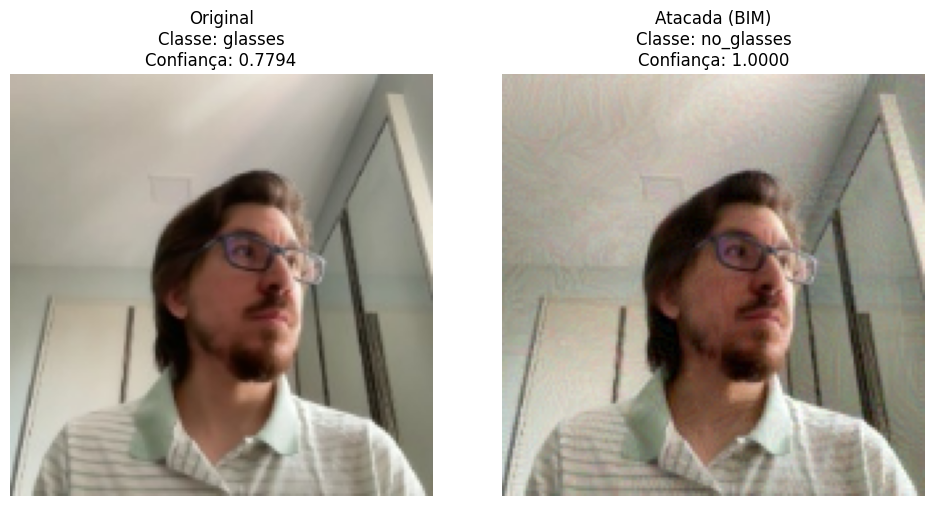

In [34]:
# Classify adversarial sample and print classification result
pred_orig = model.predict(x_input, verbose=0)[0][0]
pred_adv  = model.predict(adv_x_bim, verbose=0)[0][0]

def get_label_and_conf(p):
    label = class_names[1] if p > 0.5 else class_names[0]
    conf = p if p > 0.5 else 1 - p
    return label, conf

label_o, conf_o = get_label_and_conf(pred_orig)
label_a, conf_a = get_label_and_conf(pred_adv)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
plt.title(f"Original\nClasse: {label_o}\nConfiança: {conf_o:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(adv_x_bim[0], tf.uint8).numpy())
plt.title(f"Atacada (BIM)\nClasse: {label_a}\nConfiança: {conf_a:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()

### Exibindo uma aproximação da perturbação

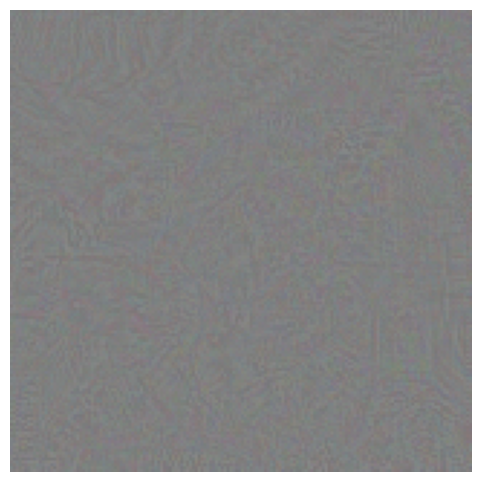

In [35]:
adv_f = adv_x_bim[0].numpy().astype('float32')
org_f = x_input[0].numpy().astype('float32')

perturbacao_real = adv_f - org_f

img_visualizacao = (perturbacao_real / 255.0) + 0.5

vmax = 0.1
vmin = -vmax

plt.figure(figsize=(6, 6))
plt.imshow(img_visualizacao, cmap='gray', vmin=vmin, vmax=vmax)
plt.axis('off')
plt.show()

## PGD


### Importando o ataque iterativo

In [36]:
from cleverhans.tf2.attacks.projected_gradient_descent import projected_gradient_descent

### Gerando o Exemplo Adversarial

In [37]:
# Craft adversarial sample
eps = 8.0
eps_iter = 1.0
nb_iter = 15

adv_x_pgd = projected_gradient_descent(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter,norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, rand_init=True, sanity_checks=False)

### Realizando a classificação do exemplo adversarial



--- RESULTADOS: PGD ---
ANTES: Classe = glasses | Confiança = 0.7794
DEPOIS (PGD): Classe = no_glasses | Confiança = 1.0000


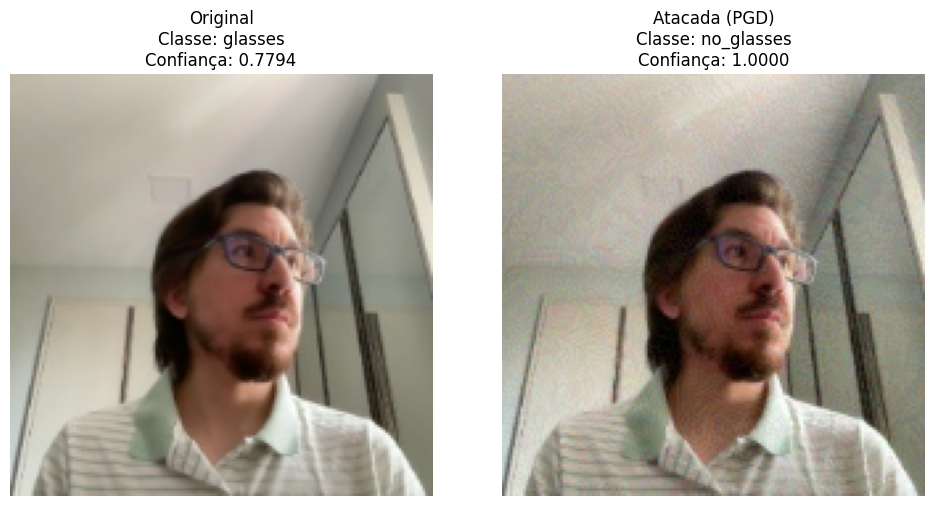

In [38]:
# Classify adversarial sample and print classification result
pred_orig = model.predict(x_input, verbose=0)[0][0]
pred_pgd  = model.predict(adv_x_pgd, verbose=0)[0][0]

class_names = train_ds.class_names

def get_label_and_conf(p):
    label = class_names[1] if p > 0.5 else class_names[0]
    conf = p if p > 0.5 else 1 - p
    return label, conf

label_o, conf_o = get_label_and_conf(pred_orig)
label_p, conf_p = get_label_and_conf(pred_pgd)

print("\n--- RESULTADOS: PGD ---")
print(f"ANTES: Classe = {label_o} | Confiança = {conf_o:.4f}")
print(f"DEPOIS (PGD): Classe = {label_p} | Confiança = {conf_p:.4f}")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
plt.title(f"Original\nClasse: {label_o}\nConfiança: {conf_o:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(adv_x_pgd[0], tf.uint8).numpy())
plt.title(f"Atacada (PGD)\nClasse: {label_p}\nConfiança: {conf_p:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()

### Exibindo uma aproximação da perturbação

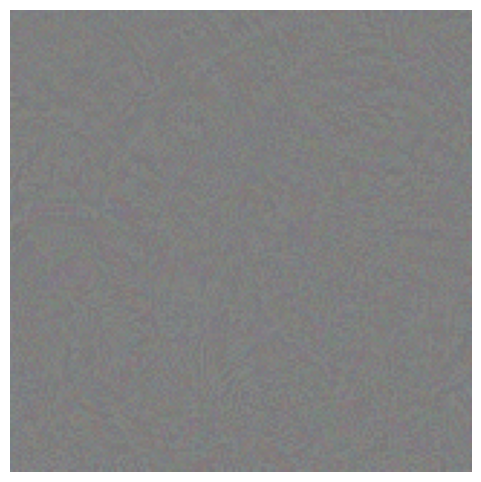

In [39]:
# Get and print adversarial perturbation
adv_f_pgd = adv_x_pgd[0].numpy().astype('float32')
org_f = x_input[0].numpy().astype('float32')

perturbacao_pgd = adv_f_pgd - org_f

img_viz_pgd = (perturbacao_pgd / 255.0) + 0.5

plt.figure(figsize=(6, 6))
plt.imshow(img_viz_pgd, cmap='gray', vmin=-0.1, vmax=0.1)
plt.axis('off')
plt.show()

## MIM

### Importando o ataque iterativo

In [40]:
from cleverhans.tf2.attacks.momentum_iterative_method import momentum_iterative_method

### Gerando o Exemplo Adversarial

In [41]:
# Craft adversarial sample
eps = 8.0
eps_iter = 1.0
nb_iter = 15

adv_x_mim = momentum_iterative_method(model_fn=model_wrapper, x=x_input, eps=eps, eps_iter=eps_iter, nb_iter=nb_iter, decay_factor=1.0, norm=np.inf, clip_min=0.0, clip_max=255.0, y=y_true_ch, sanity_checks=False)

### Realizando a classificação do exemplo adversarial



--- RESULTADOS: MIM ---
ANTES: Classe = glasses | Confiança = 0.7794
DEPOIS (MIM): Classe = no_glasses | Confiança = 1.0000


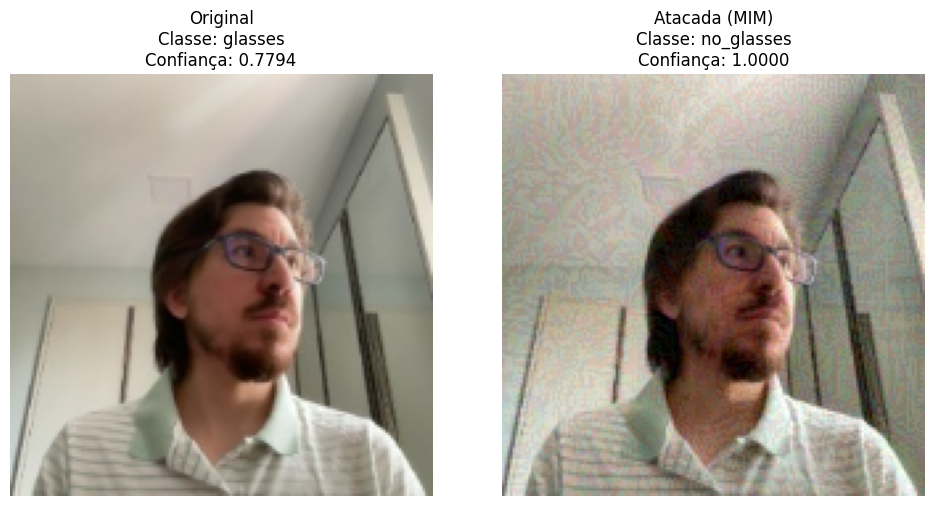

In [42]:
# Classify adversarial sample and print classification result
pred_orig = model.predict(x_input, verbose=0)[0][0]
pred_mim  = model.predict(adv_x_mim, verbose=0)[0][0]

class_names = train_ds.class_names

def get_label_and_conf(p):
    label = class_names[1] if p > 0.5 else class_names[0]
    conf = p if p > 0.5 else 1 - p
    return label, conf

label_o, conf_o = get_label_and_conf(pred_orig)
label_m, conf_m = get_label_and_conf(pred_mim)

print("\n--- RESULTADOS: MIM ---")
print(f"ANTES: Classe = {label_o} | Confiança = {conf_o:.4f}")
print(f"DEPOIS (MIM): Classe = {label_m} | Confiança = {conf_m:.4f}")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(tf.cast(x_input[0], tf.uint8).numpy())
plt.title(f"Original\nClasse: {label_o}\nConfiança: {conf_o:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(tf.cast(adv_x_mim[0], tf.uint8).numpy())
plt.title(f"Atacada (MIM)\nClasse: {label_m}\nConfiança: {conf_m:.4f}")
plt.axis('off')

plt.tight_layout()
plt.show()

### Exibindo uma aproximação da perturbação

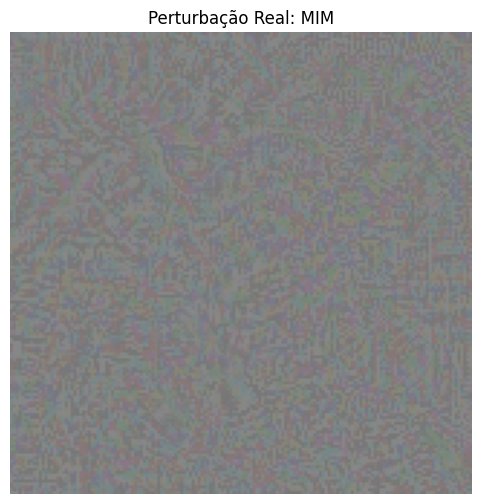

In [43]:
# Get and print adversarial perturbation
adv_f_mim = adv_x_mim[0].numpy().astype('float32')
org_f = x_input[0].numpy().astype('float32')

perturbacao_mim = adv_f_mim - org_f

img_viz_mim = (perturbacao_mim / 255.0) + 0.5

plt.figure(figsize=(6, 6))
plt.imshow(img_viz_mim, cmap='gray', vmin=-0.1, vmax=0.1)
plt.title("Perturbação Real: MIM")
plt.axis('off')
plt.show()